# Chapitre 9 - Lab : consensus et coordination avec etcd

etcd est le service de coordination répliqué par **Raft** (cours 5 et 6). Ce lab
lance une grappe de trois nœuds et vérifie sur le vrai système ce que les cours ont
simulé : révisions croissantes et CAS, baux et clés éphémères, verrou dont le bail expire
et jeton de clôture, lectures linéarisables contre lectures sérialisables sur un nœud
isolé, élection d'un nouveau leader après une panne, perte du quorum.

**Démarrer et arrêter la grappe** (depuis la racine du dépôt) :

```bash
docker compose -f docker/consistency/compose.yml -p ddia_consistency up -d
# ... exécuter le notebook ...
docker compose -f docker/consistency/compose.yml -p ddia_consistency down -v
```

Le notebook parle à etcd par sa passerelle JSON/HTTP (ports 11001 à 11003) et pilote Docker
par `subprocess` pour provoquer pannes et coupures réseau (uniquement sur les conteneurs
`ddia_consistency_*`).

**Plan.**

1. La grappe : qui est leader ?
2. Révisions et compare-and-set.
3. Baux et clés éphémères.
4. Un verrou dont le bail expire, et la clôture.
5. Lectures linéarisables et sérialisables sur un nœud isolé.
6. Panne du leader et élection.
7. Perte du quorum.

In [1]:
import base64
import json
import subprocess
import threading
import time
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)

PORTS = {"etcd1": 11001, "etcd2": 11002, "etcd3": 11003}
CONT = {n: f"ddia_consistency_{n}" for n in PORTS}
NET = "ddia_consistency_default"

b64 = lambda s: base64.b64encode(s.encode()).decode()
unb = lambda s: base64.b64decode(s).decode()

def api(node, path, body, timeout=3.0):
    """Appel de la passerelle JSON d'etcd (API v3) sur un nœud."""
    req = urllib.request.Request(f"http://127.0.0.1:{PORTS[node]}/v3/{path}", data=json.dumps(body).encode(), method="POST")
    with urllib.request.urlopen(req, timeout=timeout) as r:
        return json.loads(r.read())

def put(node, key, value, lease=None, timeout=3.0):
    body = {"key": b64(key), "value": b64(value)}
    if lease:
        body["lease"] = lease
    return api(node, "kv/put", body, timeout)

def get(node, key, serializable=False, timeout=3.0):
    r = api(node, "kv/range", {"key": b64(key), "serializable": serializable}, timeout)
    kvs = r.get("kvs", [])
    return (unb(kvs[0]["value"]) if kvs else None), r["header"]

def docker(*args):
    return subprocess.run(["docker", *args], capture_output=True, text=True)

def ctl(node, *args):
    """etcdctl exécuté DANS le conteneur (fonctionne même s'il est coupé du réseau)."""
    p = docker("exec", CONT[node], "etcdctl", "--endpoints=127.0.0.1:2379", "--command-timeout=2s", *args)
    return p.returncode, p.stdout.strip(), p.stderr.strip()

def statut():
    rows, ids = [], {}
    for n in PORTS:
        try:
            s = api(n, "maintenance/status", {}, timeout=1.0)
            ids[s["header"]["member_id"]] = n
            rows.append(dict(nœud=n, id=s["header"]["member_id"], leader_id=s.get("leader"), mandat=int(s["raftTerm"]),
                             indice_raft=int(s["raftIndex"]), révision=int(s["header"]["revision"]),
                             erreur=";".join(s.get("errors", []))))
        except Exception as e:
            rows.append(dict(nœud=n, erreur=type(e).__name__))
    df = pd.DataFrame(rows)
    df["leader"] = df.get("leader_id", pd.Series(dtype=object)).map(ids)
    return df.drop(columns=[c for c in ("id", "leader_id") if c in df.columns])

def leader():
    df = statut()
    vals = df["leader"].dropna().unique() if "leader" in df else []
    return vals[0] if len(vals) == 1 else None

def attendre_grappe(timeout=30):
    t0 = time.time()
    while time.time() - t0 < timeout:
        df = statut()
        if "leader" in df and df["leader"].notna().all() and df["leader"].nunique() == 1 and (df["erreur"].fillna("") == "").all():
            return df
        time.sleep(0.3)
    raise RuntimeError("la grappe etcd n'est pas prête : démarrez-la avec docker compose (voir en tête)")

_ = attendre_grappe()

## 1. La grappe : qui est leader ? (section *Membership and Coordination Services*)

Chaque nœud rapporte l'identifiant du leader qu'il connaît, son **mandat** Raft (term),
l'indice de son journal Raft et la **révision** du magasin clé-valeur.

In [2]:
st0 = attendre_grappe()
st0

,nœud,mandat,indice_raft,révision,erreur,leader
0,etcd1,6,897,834,,etcd2
1,etcd2,6,897,834,,etcd2
2,etcd3,6,897,834,,etcd2


Les trois nœuds s'accordent sur un même leader et un même mandat. Le mandat vaut 2 ou plus :
la grappe a élu son premier leader au démarrage (et davantage si elle a déjà subi des
pannes). Toutes les requêtes d'écriture passeront par ce leader, quel que soit le nœud
contacté par le client.

> **À retenir.** etcd est un journal Raft de 3 nœuds : un leader par mandat, et un état
> (révision, indice) que tous les nœuds partagent.

## 2. Révisions et compare-and-set (sections *Implementing linearizable storage using total order broadcast* et *Membership and Coordination Services*)

Chaque écriture incrémente la **révision** globale ; chaque clé garde sa révision de
création (`create_revision`) et de dernière modification (`mod_revision`). Les
**transactions** d'etcd sont des CAS généralisés : « si telle comparaison est vraie, faire
ceci, sinon cela ». Réservons un nom d'utilisateur avec la comparaison
`create_revision == 0` (la clé n'existe pas) : 20 clients concurrents, répartis sur les
trois nœuds, tentent de réserver le même nom.

In [3]:
def reserver(node, nom, user):
    r = api(node, "kv/txn", {"compare": [{"key": b64(nom), "target": "CREATE", "result": "EQUAL", "create_revision": "0"}],
                             "success": [{"request_put": {"key": b64(nom), "value": b64(user)}}]})
    return r.get("succeeded", False), int(r["header"]["revision"])

nom = f"/utilisateurs/bob-{int(time.time())}"
resultats = {}
def tente(i):
    resultats[i] = reserver(list(PORTS)[i % 3], nom, f"client{i}")
threads = [threading.Thread(target=tente, args=(i,)) for i in range(20)]
for t in threads: t.start()
for t in threads: t.join()
gagnants = [i for i, (ok, _) in resultats.items() if ok]
valeur, _ = get("etcd2", nom)
print(f"réservations réussies : {len(gagnants)} (client{gagnants[0]}) ; propriétaire lu sur etcd2 : {valeur}")
revs = []
for k in range(5):
    r = put(list(PORTS)[k % 3], "compteur", str(k))
    revs.append(int(r["header"]["revision"]))
print("révisions de 5 écritures successives (sur 3 nœuds différents) :", revs)

réservations réussies : 1 (client0) ; propriétaire lu sur etcd2 : client0
révisions de 5 écritures successives (sur 3 nœuds différents) : [836, 837, 838, 839, 840]


Une seule des 20 réservations réussit, quel que soit le nœud contacté : le CAS est
linéarisable parce qu'il passe par le journal Raft. Les révisions de cinq écritures
successives, adressées à des nœuds différents, sont strictement croissantes : c'est l'ordre
total du journal partagé, et c'est ce numéro qui sert de **jeton de clôture**.

> **À retenir.** Une transaction etcd est un CAS linéarisable ; la révision est un compteur
> global croissant, utilisable comme identifiant ordonné ou comme jeton.

## 3. Baux et clés éphémères (section *Membership and Coordination Services*)

Une clé attachée à un **bail** (lease) disparaît quand le bail expire. Un client vivant
prolonge son bail par des battements (`keepalive`). Enregistrons deux instances d'un
service avec des baux de 3 s : l'une envoie des battements chaque seconde, l'autre
« meurt » après 2 s. On observe les clés toutes les 0,25 s.

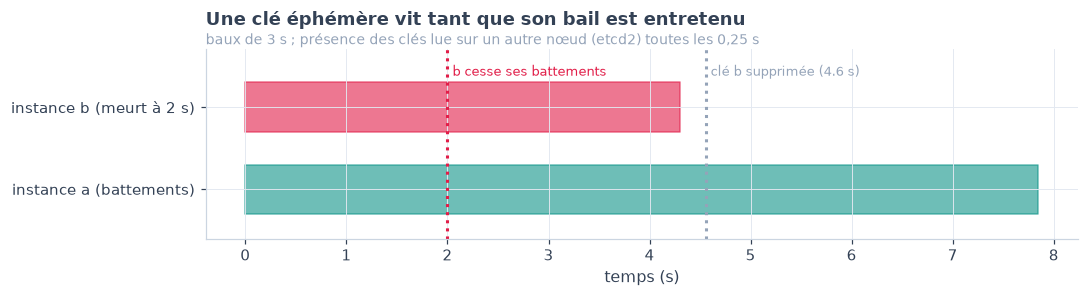

In [4]:
la = api("etcd1", "lease/grant", {"TTL": 3})["ID"]
lb = api("etcd1", "lease/grant", {"TTL": 3})["ID"]
put("etcd1", "/services/api/a", "10.0.0.1", lease=la)
put("etcd1", "/services/api/b", "10.0.0.2", lease=lb)
obs, t0, dernier = [], time.time(), {"a": 0.0, "b": 0.0}
while time.time() - t0 < 8:
    t = time.time() - t0
    for inst, lid, vivant_jusqua in [("a", la, 99), ("b", lb, 2.0)]:
        if t < vivant_jusqua and t - dernier[inst] >= 1.0:
            api("etcd1", "lease/keepalive", {"ID": lid})
            dernier[inst] = t
    obs.append(dict(t=t, a=get("etcd2", "/services/api/a")[0] is not None, b=get("etcd2", "/services/api/b")[0] is not None))
    time.sleep(0.25)
O = pd.DataFrame(obs)
fig, ax = plt.subplots(figsize=(10, 2.8))
for k, (inst, c) in enumerate([("a", TEAL), ("b", ROSE)]):
    ax.fill_between(O.t, k - 0.3, k + 0.3, where=O[inst], color=c, alpha=0.6, step="post")
ax.axvline(2.0, color=ROSE, ls=":")
disparition = O.t[~O.b].min()
ax.axvline(disparition, color=GRAY, ls=":")
ax.text(2.05, 1.38, "b cesse ses battements", color=ROSE, fontsize=8.5)
ax.text(disparition + 0.05, 1.38, f"clé b supprimée ({disparition:.1f} s)", color=GRAY, fontsize=8.5)
ax.set_yticks([0, 1], ["instance a (battements)", "instance b (meurt à 2 s)"])
ax.set_ylim(-0.6, 1.7); ax.set_xlabel("temps (s)")
ax.set_title("Une clé éphémère vit tant que son bail est entretenu")
subtitle(ax, "baux de 3 s ; présence des clés lue sur un autre nœud (etcd2) toutes les 0,25 s")
plt.tight_layout(); plt.show()

La clé de b disparaît environ 3 s après son dernier battement (la durée du bail), celle de
a reste. Un client qui surveille le préfixe `/services/api/` en serait notifié : c'est la
détection de pannes d'un service de coordination, utilisée pour la découverte de services
ou la répartition du travail.

> **À retenir.** Bail + battements = détection de pannes : le service supprime les clés
> d'un client qui ne donne plus signe de vie pendant la durée du bail.

## 4. Un verrou dont le bail expire, et la clôture (section *Membership and Coordination Services*)

etcd fournit un service de verrou : `lock` crée une clé sous le nom du verrou, attachée à un
bail, et ne rend la main que lorsque c'est la plus ancienne (la recette de la clé
séquentielle surveillant son prédécesseur). Le client A prend le verrou avec un bail de 3 s
puis se « fige » (plus de battements, comme pendant une pause du ramasse-miettes) ; le
client B attend le verrou. Quand A se réveille, il tente d'écrire dans la ressource
protégée, de deux façons : naïvement, ou par une transaction qui vérifie que **sa** clé de
verrou existe toujours (forme de clôture propre à etcd, équivalente à la vérification d'un
jeton par la ressource).

In [5]:
verrou = f"verrou-{int(time.time())}"
lA = api("etcd1", "lease/grant", {"TTL": 3})["ID"]
lB = api("etcd2", "lease/grant", {"TTL": 30})["ID"]
T0 = time.time()
kA = api("etcd1", "lock/lock", {"name": b64(verrou), "lease": lA})
tA = time.time() - T0
revA = int(kA["header"]["revision"]); cleA = unb(kA["key"])
evB = {}
def client_B():
    k = api("etcd2", "lock/lock", {"name": b64(verrou), "lease": lB}, timeout=30)
    evB.update(t=time.time() - T0, rev=int(k["header"]["revision"]), cle=unb(k["key"]))
    put("etcd2", "/ressource", "écrit par B")
    evB["t_write"] = time.time() - T0
thB = threading.Thread(target=client_B); thB.start()
time.sleep(5.0)                                      # A est figé : aucun battement
t_reveil = time.time() - T0
naif = put("etcd1", "/ressource-naive", "écrit par A (zombie)")
garde = api("etcd1", "kv/txn", {"compare": [{"key": b64(cleA), "target": "CREATE", "result": "EQUAL", "create_revision": str(revA)}],
                               "success": [{"request_put": {"key": b64("/ressource"), "value": b64("écrit par A (zombie)")}}]})
t_zombie = time.time() - T0
thB.join()
print(f"A obtient le verrou à {tA:.2f} s (révision {revA}) ; B l'obtient à {evB['t']:.2f} s (révision {evB['rev']})")
print("écriture naïve de A acceptée :", "header" in naif, "; écriture gardée de A acceptée :", garde.get("succeeded", False))
print("contenu final de /ressource :", get("etcd3", "/ressource")[0])

A obtient le verrou à 0.00 s (révision 846) ; B l'obtient à 3.33 s (révision 849)
écriture naïve de A acceptée : True ; écriture gardée de A acceptée : False
contenu final de /ressource : écrit par B


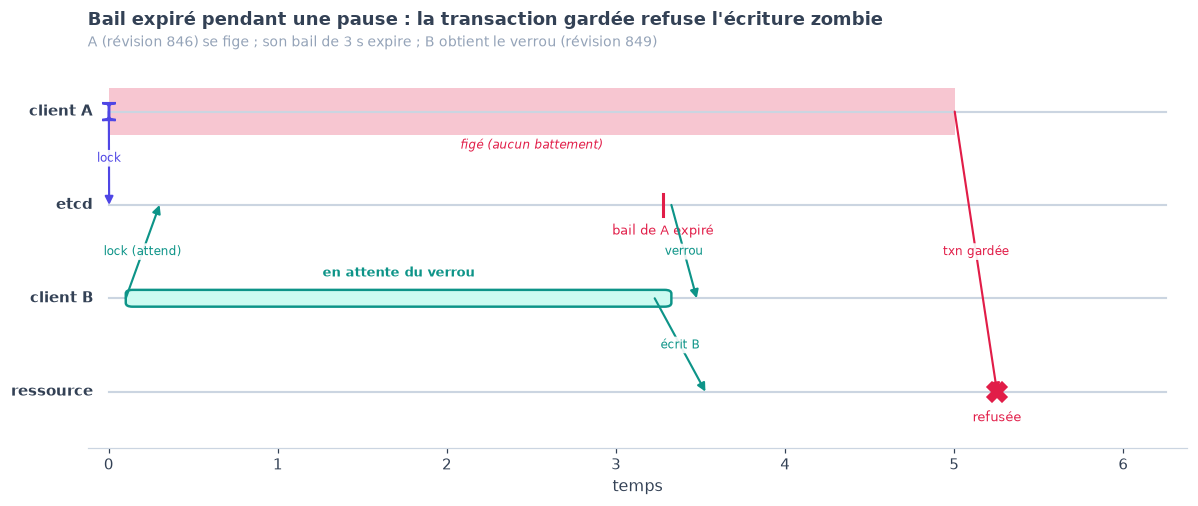

In [6]:
st = SpaceTime(["client A", "etcd", "client B", "ressource"], t_max=max(t_zombie, t_reveil + 0.25) + 1, width=11,
               title="Bail expiré pendant une pause : la transaction gardée refuse l'écriture zombie",
               subtitle=f"A (révision {revA}) se fige ; son bail de 3 s expire ; B obtient le verrou (révision {evB['rev']})")
st.msg("client A", 0.0, "etcd", tA, "lock", color=INDIGO)
st.op("client A", 0.0, tA, "", color=INDIGO)
st.span("client A", tA, t_reveil, "figé (aucun battement)", color=ROSE)
st.msg("client B", 0.1, "etcd", 0.3, "lock (attend)", color=TEAL)
st.op("client B", 0.1, evB["t"], "en attente du verrou", color=TEAL)
st.event("etcd", evB["t"] - 0.05, "bail de A expiré", kind="tick", color=ROSE)
st.msg("etcd", evB["t"], "client B", evB["t"] + 0.15, "verrou", color=TEAL)
st.msg("client B", evB["t_write"] - 0.1, "ressource", evB["t_write"] + 0.2, "écrit B", color=TEAL)
st.msg("client A", t_reveil, "ressource", max(t_zombie, t_reveil + 0.25), "txn gardée", color=ROSE)
st.event("ressource", max(t_zombie, t_reveil + 0.25), "refusée", kind="crash")
st.show()

B obtient le verrou un peu plus de 3 s après A : c'est l'expiration du bail de A, qui a
supprimé sa clé de verrou. Au réveil de A, l'écriture naïve passe (rien ne l'empêche) : A
croit toujours tenir le verrou. La transaction gardée, elle, échoue, car la clé de verrou
de A (créée à la révision `revA`) n'existe plus. La révision de B est plus grande que celle
de A : une ressource extérieure à etcd pourrait aussi bien refuser toute écriture portant
un jeton inférieur au plus grand déjà vu.

> **À retenir.** Un verrou à bail n'empêche pas un client figé de se croire détenteur ; la
> protection vient de la vérification, au moment de l'écriture, que le verrou (ou son
> jeton) est toujours valide.

## 5. Lectures linéarisables et sérialisables sur un nœud isolé (section *Implementing Linearizable Systems*)

etcd offre deux niveaux de lecture : **linéarisable** (par défaut : le nœud vérifie auprès
d'un quorum, via le leader, qu'il a bien tout le journal validé) et **sérialisable** (le
nœud répond avec son état local, éventuellement en retard). Coupons du réseau un nœud
**suiveur**, écrivons une nouvelle valeur par un autre nœud, puis lisons sur le nœud isolé
(avec `etcdctl` exécuté dans son conteneur).

In [7]:
attendre_grappe()
L = leader()
isole = [n for n in PORTS if n != L][0]
autre = [n for n in PORTS if n not in (L, isole)][0]
put(autre, "score", "2-1, 89e minute")
time.sleep(0.5)
docker("network", "disconnect", NET, CONT[isole])
time.sleep(0.5)
put(autre, "score", "3-1, FINAL")
lect = []
for mode in ("s", "l"):
    t = time.time()
    rc, out, err = ctl(isole, "get", "score", f"--consistency={mode}", "--print-value-only")
    lect.append(dict(nœud=isole, lecture="sérialisable" if mode == "s" else "linéarisable", durée_s=time.time() - t,
                     résultat=out if rc == 0 else f"erreur : {err.splitlines()[-1][:60] if err else rc}"))
lect.append(dict(nœud=autre, lecture="linéarisable", durée_s=np.nan, résultat=get(autre, "score")[0]))
docker("network", "connect", "--alias", isole, NET, CONT[isole])   # garder le nom DNS du service
pd.DataFrame(lect)

,nœud,lecture,durée_s,résultat
0,etcd1,sérialisable,0.041,"2-1, 89e minute"
1,etcd1,linéarisable,2.039,erreur : Error: context deadline exceeded
2,etcd3,linéarisable,NaN,"3-1, FINAL"


Le nœud isolé répond **immédiatement** à la lecture sérialisable... avec l'ancien score : il
n'a pas reçu la dernière écriture. La lecture linéarisable, elle, **échoue** après le délai
(le nœud ne peut pas joindre de quorum pour confirmer qu'il est à jour) : c'est le choix
« CP » de CAP, en petit. Les deux nœuds de la majorité, eux, voient le score final. (C'est
exactement la situation d'Inès et Bastien du cours 1, si l'application lisait en mode
sérialisable.)

**Le coût des lectures linéarisables.** Mesurons, sur la grappe rétablie, 300 lectures de
chaque type adressées à un suiveur.

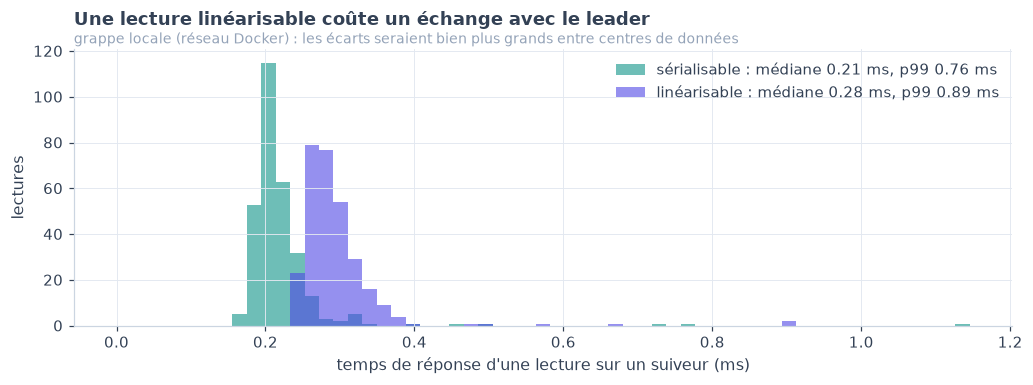

In [8]:
attendre_grappe()
L = leader()
suiveur = [n for n in PORTS if n != L][0]
lat = {"sérialisable": [], "linéarisable": []}
for k in range(600):
    mode = "sérialisable" if k % 2 == 0 else "linéarisable"
    t = time.perf_counter()
    get(suiveur, "score", serializable=(mode == "sérialisable"))
    lat[mode].append((time.perf_counter() - t) * 1000)
fig, ax = plt.subplots(figsize=(9.5, 3.6))
bins = np.linspace(0, np.percentile(lat["linéarisable"], 99.5), 60)
for mode, c in [("sérialisable", TEAL), ("linéarisable", INDIGO)]:
    v = np.array(lat[mode])
    ax.hist(v, bins=bins, alpha=0.6, color=c, label=f"{mode} : médiane {np.median(v):.2f} ms, p99 {np.percentile(v, 99):.2f} ms")
ax.set_xlabel("temps de réponse d'une lecture sur un suiveur (ms)"); ax.set_ylabel("lectures")
ax.set_title("Une lecture linéarisable coûte un échange avec le leader")
subtitle(ax, "grappe locale (réseau Docker) : les écarts seraient bien plus grands entre centres de données")
ax.legend()
plt.tight_layout(); plt.show()

Même sur un réseau local, la lecture linéarisable est plus lente que la lecture sérialisable :
le suiveur doit demander au leader son indice de validation (qui lui-même confirme son
statut auprès d'un quorum) et attendre d'avoir appliqué le journal jusque-là. Entre centres
de données, cet écart se compterait en dizaines de millisecondes.

> **À retenir.** Sérialisable : rapide, disponible même isolé, mais potentiellement périmé.
> Linéarisable : à jour, mais un aller-retour de plus, et indisponible sans quorum.

## 6. Panne du leader et élection (section *Epoch numbering and quorums*)

Un client écrit en continu (une écriture toutes les 20 ms, délai d'attente de 0,5 s) par un
nœud qui restera vivant. On **gèle** le conteneur du leader (`docker pause` : le processus
ne répond plus, comme pendant une longue pause), on mesure le temps sans écriture réussie
et on observe le nouveau mandat.

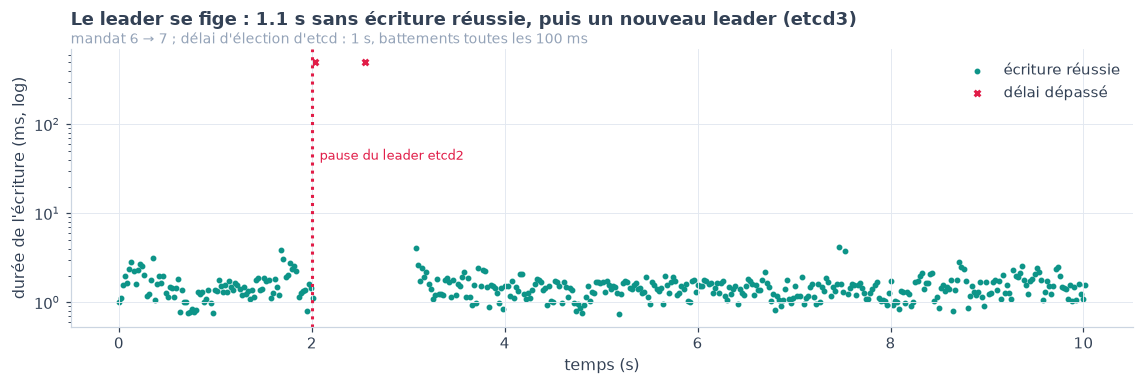

,nœud,mandat,indice_raft,révision,erreur,leader
0,etcd1,7,1358,1270,,etcd3
1,etcd2,7,1358,1270,,etcd3
2,etcd3,7,1358,1270,,etcd3


In [9]:
attendre_grappe()
L = leader()
mandat_avant = int(statut().set_index("nœud").loc[L, "mandat"])
client_node = [n for n in PORTS if n != L][0]
journal, stop = [], threading.Event()
def ecrivain():
    k = 0
    while not stop.is_set():
        t = time.time()
        try:
            put(client_node, "battement-client", str(k), timeout=0.5)
            journal.append((t - T0, time.time() - t, True))
        except Exception:
            journal.append((t - T0, time.time() - t, False))
        k += 1
        time.sleep(0.02)
T0 = time.time()
th = threading.Thread(target=ecrivain); th.start()
time.sleep(2.0)
t_pause = time.time() - T0
docker("pause", CONT[L])
time.sleep(6.0)
docker("unpause", CONT[L])
time.sleep(2.0)
stop.set(); th.join()
J = pd.DataFrame(journal, columns=["t", "durée", "ok"])
apres = statut()
nouveau = leader()
ok_t = J[J.ok].t.values
trou = max(b - a for a, b in zip(ok_t[:-1], ok_t[1:]))
fig, ax = plt.subplots(figsize=(10.5, 3.6))
ax.scatter(J.t[J.ok], J.durée[J.ok] * 1000, s=8, color=TEAL, label="écriture réussie")
ax.scatter(J.t[~J.ok], J.durée[~J.ok] * 1000, s=14, color=ROSE, marker="x", label="délai dépassé")
ax.axvline(t_pause, color=ROSE, ls=":")
ax.text(t_pause + 0.08, 40, f"pause du leader {L}", color=ROSE, fontsize=8.5)
ax.set_yscale("log")
ax.set_xlabel("temps (s)"); ax.set_ylabel("durée de l'écriture (ms, log)")
ax.set_title(f"Le leader se fige : {trou:.1f} s sans écriture réussie, puis un nouveau leader ({nouveau})")
subtitle(ax, f"mandat {mandat_avant} → {int(apres.mandat.max())} ; délai d'élection d'etcd : 1 s, battements toutes les 100 ms")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()
apres

Pendant une à deux secondes (le délai d'élection d'etcd, tiré entre 1 et 2 s, plus le temps du vote),
les écritures échouent : il n'y a plus de leader joignable. Puis un autre nœud est élu dans
un mandat supérieur, et les écritures reprennent avec leur latence habituelle. Quand
l'ancien leader est dégelé, il découvre le mandat supérieur et redevient suiveur : il n'y a
jamais eu deux leaders dans le même mandat.

> **À retenir.** La bascule est automatique et sûre ; elle coûte environ un délai
> d'élection d'indisponibilité en écriture, comme dans nos simulations de Raft.

## 7. Perte du quorum (section *Limitations of consensus*)

Arrêtons deux nœuds sur trois : le survivant est une minorité. Peut-il encore écrire ?
Lire ?

In [10]:
attendre_grappe()
survivant = "etcd1"
for n in ("etcd2", "etcd3"):
    docker("stop", "-t", "1", CONT[n])
time.sleep(1.5)
res = []
t = time.time()
try:
    put(survivant, "pendant-la-panne", "x", timeout=3)
    res.append(dict(opération="écriture", résultat="acceptée", durée_s=time.time() - t))
except Exception as e:
    res.append(dict(opération="écriture", résultat=f"échec ({type(e).__name__})", durée_s=time.time() - t))
for ser in (False, True):
    t = time.time()
    try:
        v, _ = get(survivant, "score", serializable=ser, timeout=3)
        res.append(dict(opération="lecture " + ("sérialisable" if ser else "linéarisable"), résultat=f"« {v} »", durée_s=time.time() - t))
    except Exception as e:
        res.append(dict(opération="lecture " + ("sérialisable" if ser else "linéarisable"), résultat=f"échec ({type(e).__name__})",
                        durée_s=time.time() - t))
for n in ("etcd2", "etcd3"):
    docker("start", CONT[n])
t_rep = time.time()
attendre_grappe(60)
res.append(dict(opération="retour de la majorité", résultat=f"leader {leader()}", durée_s=time.time() - t_rep))
pd.DataFrame(res)

,opération,résultat,durée_s
0,écriture,échec (TimeoutError),3.004e+00
1,lecture linéarisable,échec (TimeoutError),3.003e+00
2,lecture sérialisable,"« 3-1, FINAL »",9.398e-04
3,retour de la majorité,leader etcd3,9.215e-01


Sans majorité, le survivant ne peut ni valider une écriture ni servir une lecture
linéarisable : les deux échouent après le délai. Il sert encore des lectures sérialisables
(son état local, figé). Dès que les deux nœuds redémarrent, la grappe élit un leader et tout
reprend, sans aucune perte : les entrées validées étaient sur disque dans au moins deux
nœuds. C'est la limite fondamentale : $2f + 1$ nœuds tolèrent $f$ pannes, pas une de plus.

> **À retenir.** Une grappe de consensus sans majorité s'arrête (elle reste sûre, mais n'est
> plus disponible) ; seules des lectures sérialisables, potentiellement périmées, restent
> possibles.